# 04b — Nuages complémentaires pour valider Noether-SurPhiN

**Objectif** : Corriger les artefacts du premier jeu de résultats et produire des nuages ciblés pour chaque question ouverte.

**Problèmes identifiés dans le premier CSV** :
- `adiabatic_ncomp` et `depth_fraction` : copeau = 0.0 partout (discrétisation, pas de variance entre graines).
- `pers_energy` / `pers_mass` : systématiquement 'turbulent' (hypersensibles aux échelles absolues).
- N3 : n_samples = 2 (grille T trop coarse, 3 points seulement).
- N2 : pers_energy turbulent en dimension (projection au lieu de plongement explicite).

**5 familles historiques A–E** (les familles complémentaires F/H/I/J/K du protocole 04c sont configurées plus bas) :

| Famille | But | Paramètre varie | Fixe | N nuages |
|---|---|---|---|---|
| **A** | Grille fine en T (résoudre N3) | T = 0.10..0.80 (8 pts) | g=0.35, 12 graines | 96 |
| **B** | Témoins topologiques (valider le module) | type de signal | g=0, T=0, 12 graines | 36 |
| **C** | Dimensions d'embedding explicites (résoudre N2) | m = 2..8 (7 pts) | g=0.35, T=0.40, 12 graines | 84 |
| **D** | Transition de régime g (localiser le seuil) | g = 0.05..0.70 (11 pts) | T=0.40, 12 graines | 132 |
| **E** | Perturbations non-conservatives (tester sigma) | type de bruit | g=0.35, T=0.40, 12 graines | 48 |

**Convention de nommage** (étendue) :
```
X_fam<A-E>_g<G>_T<T>_m<M>_seed<S>.npy
```
Le champ `fam` permet de séparer les familles dans le parsing.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# -----------------------------------------------------------------------------
# CONFIGURATION — ADAPTER ICI
# -----------------------------------------------------------------------------
BASE_DIR = Path.cwd().resolve()
for _candidate in (BASE_DIR, *BASE_DIR.parents):
    if (_candidate / "noether_persistence.py").is_file():
        BASE_DIR = _candidate
        break
else:
    raise FileNotFoundError("Racine du projet introuvable : noether_persistence.py absent des parents du dossier courant")
OUT_DIR = BASE_DIR / "nuages_complementaires"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Paramètres de construction (cohérents avec 04a)
N_SAMPLES = 4000      # longueur du signal brut
N_POINTS  = 300       # points conservés dans le nuage final
TAKENS_TAU = 7        # délai d'embedding

# Graines
SEEDS = list(range(35))

print(f"Dossier de sortie des nuages : {OUT_DIR.resolve()}")

Dossier de sortie des nuages : C:\Users\anton\source\Takens_H0_Simondon_in_PHY_noether-surphin-suite_forPUB\nuages_complementaires


In [2]:
# -----------------------------------------------------------------------------
# 2. SIGNAUX DE BASE (réutilisés de 04a + témoins)
# -----------------------------------------------------------------------------

def signal_sinus(rng, n):
    t = np.linspace(0.0, 30.0 * np.pi, n)
    freq = rng.uniform(1.0, 2.5)
    return np.sin(freq * t) + 0.3 * np.sin(3.7 * freq * t + rng.uniform(0, np.pi))

def signal_rossler(rng, n, dt=0.03):
    a, b, c = 0.2, 0.2, rng.uniform(5.0, 6.5)
    x, y, z = np.empty(n), np.empty(n), np.empty(n)
    x[0], y[0], z[0] = rng.normal(scale=0.5, size=3)
    for i in range(n - 1):
        x[i+1] = x[i] + dt * (-y[i] - z[i])
        y[i+1] = y[i] + dt * (x[i] + a * y[i])
        z[i+1] = z[i] + dt * (b + z[i] * (x[i] - c))
    return x

def signal_marche(rng, n):
    steps = rng.normal(size=n)
    kernel = np.array([0.5, 0.3, 0.15, 0.05])
    steps = np.convolve(steps, kernel, mode="same")
    return np.cumsum(steps)

# --- Témoins topologiques (Famille B) ---

def signal_double_puits(rng, n, dt=0.01):
    """
    Double-puits forcé : dx = v, dv = -dV/dx + noise
    V(x) = -x^2/2 + x^4/4 (deux puits stables en x = ±1).
    Topologie attendue : 2 composantes connexes séparées si le bruit est faible.
    """
    x, v = np.empty(n), np.empty(n)
    x[0] = rng.choice([-0.5, 0.5]) + rng.normal(scale=0.1)
    v[0] = rng.normal(scale=0.1)
    for i in range(n - 1):
        force = x[i] - x[i]**3  # -dV/dx = x - x^3
        v[i+1] = v[i] + dt * (force - 0.1 * v[i]) + np.sqrt(dt)*0.2*rng.normal()
        x[i+1] = x[i] + dt * v[i+1]
    return x

def signal_rossler_pur(rng, n, dt=0.03):
    """Rössler sans variation de c (topologie stable attendue)."""
    a, b, c = 0.2, 0.2, 5.7
    x, y, z = np.empty(n), np.empty(n), np.empty(n)
    x[0], y[0], z[0] = rng.normal(scale=0.5, size=3)
    for i in range(n - 1):
        x[i+1] = x[i] + dt * (-y[i] - z[i])
        y[i+1] = y[i] + dt * (x[i] + a * y[i])
        z[i+1] = z[i] + dt * (b + z[i] * (x[i] - c))
    return x

SIGNAL_FAMILIES = {
    "sinus": signal_sinus,
    "rossler": signal_rossler,
    "marche": signal_marche,
    "double_puits": signal_double_puits,
    "rossler_pur": signal_rossler_pur,
}
print("Familles disponibles :", list(SIGNAL_FAMILIES))

Familles disponibles : ['sinus', 'rossler', 'marche', 'double_puits', 'rossler_pur']


In [3]:
# -----------------------------------------------------------------------------
# 3. FONCTIONS DE CONSTRUCTION (identiques à 04a, m paramétrable)
# -----------------------------------------------------------------------------

def coupler(s1, s2, g, rng=None):
    """Couplage linéaire symétrique de force g."""
    return s1 + g * s2, s2 + g * s1

def perturber(s, T, rng):
    """Bruit gaussien proportionnel à l'écart-type du signal."""
    sigma = s.std() if s.std() > 0 else 1.0
    return s + T * sigma * rng.normal(size=s.shape)

def plonger_takens(s, m, tau):
    """Plongement retardé (m, tau) d'un signal 1D -> tableau (n, m)."""
    n = len(s) - (m - 1) * tau
    if n <= 0:
        raise ValueError(f"signal trop court pour m={m}, tau={tau}")
    idx = np.arange(n)[:, None] + tau * np.arange(m)[None, :]
    return s[idx]

def standardiser(X):
    """Centre-réduit colonne par colonne."""
    mu = X.mean(axis=0, keepdims=True)
    sd = X.std(axis=0, keepdims=True)
    sd[sd == 0] = 1.0
    return (X - mu) / sd

def sous_echantillonner(X, n_points):
    if len(X) > n_points:
        sel = np.linspace(0, len(X) - 1, n_points).round().astype(int)
        return X[sel]
    return X

def construire_nuage(g, T, seed, m=3, familles=("sinus", "rossler")):
    """
    Construit un nuage (N_POINTS, m * len(familles)) pour (g, T, seed, m).
    Compatible avec le parseur : X_famA_g0.35_T0.40_m3_seed7.npy
    """
    rng = np.random.default_rng(seed)
    signaux = [SIGNAL_FAMILIES[f](rng, N_SAMPLES) for f in familles]
    if len(signaux) == 1:
        signaux.append(signaux[0].copy())
    s1, s2 = coupler(signaux[0], signaux[1], g)
    s1, s2 = perturber(s1, T, rng), perturber(s2, T, rng)
    canaux = [plonger_takens(s1, m, TAKENS_TAU),
              plonger_takens(s2, m, TAKENS_TAU)]
    X = np.hstack(canaux)
    X = sous_echantillonner(X, N_POINTS)
    return standardiser(X)

print("Fonctions de construction prêtes.")

Fonctions de construction prêtes.


## Famille A — Grille fine en T (résoudre le problème N3)

**Problème** : Le premier CSV avait n_samples = 2 pour N3 (3 valeurs de T seulement : 0.25, 0.40, 0.55). `depth_fraction` et `adiabatic_ncomp` apparaissaient comme conservatifs car la discrétisation était trop coarse pour capturer leur sensibilité à T.

**Solution** : 8 valeurs de T de 0.10 à 0.80, g fixé à 0.35 (l'arrête robuste), 12 graines.

**Question Noetherienne** : À partir de quel seuil T_crit la charge `depth_fraction` cesse d'être adiabatique et devient turbulent ?

In [4]:
# -----------------------------------------------------------------------------
# FAMILLE A : Grille fine en T
# -----------------------------------------------------------------------------
G_A = 0.35
T_VALUES_FINE = np.round(np.linspace(0.10, 0.80, 8), 2)  # 8 points
M_A = 3

chemins_A = []
for T in T_VALUES_FINE:
    for seed in SEEDS:
        X = construire_nuage(G_A, T, seed, m=M_A)
        chemin = OUT_DIR / f"X_famA_g{G_A:.2f}_T{T:.2f}_m{M_A}_seed{seed}.npy"
        np.save(chemin, X.astype(np.float64))
        chemins_A.append(chemin)

print(f"[Famille A] {len(chemins_A)} nuages générés")
print("T values :", T_VALUES_FINE)

[Famille A] 280 nuages générés
T values : [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8]


## Famille B — Témoins topologiques (valider le module Noether)

**Problème** : On ne sait pas si le module Noether distingue correctement un signal à topologie stable d'un signal à topologie instable.

**Solution** : 3 signaux témoins sans couplage (g=0) et sans bruit (T=0), 12 graines chacun :
- `rossler_pur` : attracteur chaotique bien formé, topologie H0 stable (regime attendu : **conservatif**).
- `double_puits` : deux puits de potentiel, transitions rares. Si les transitions sont peu fréquentes, H0 doit montrer 2 composantes persistantes (regime attendu : **adiabatique** sous graine).
- `sinus` : cycle limite parfait, topologie triviale (1 composante). Regime attendu : **conservatif** (toutes les graines identiques en topologie).

**Question Noetherienne** : Le copeau médian est-il nul pour les signaux déterministes purs ?

In [5]:
# -----------------------------------------------------------------------------
# FAMILLE B : Témoins topologiques (g=0, T=0, m=3)
# -----------------------------------------------------------------------------
temoins = ["rossler_pur", "double_puits", "sinus"]
M_B = 3
chemins_B = []

for témoin in temoins:
    for seed in SEEDS:
        # On force une seule famille (pas de couplage réel, g=0)
        rng = np.random.default_rng(seed)
        s = SIGNAL_FAMILIES[témoin](rng, N_SAMPLES)
        X = plonger_takens(s, M_B, TAKENS_TAU)
        X = sous_echantillonner(X, N_POINTS)
        X = standardiser(X)
        chemin = OUT_DIR / f"X_famB_{témoin}_g0.00_T0.00_m{M_B}_seed{seed}.npy"
        np.save(chemin, X.astype(np.float64))
        chemins_B.append(chemin)

print(f"[Famille B] {len(chemins_B)} nuages générés")
print("Témoins :", temoins)

[Famille B] 105 nuages générés
Témoins : ['rossler_pur', 'double_puits', 'sinus']


## Famille C — Dimensions d'embedding explicites (résoudre N2)

**Problème** : Dans le premier test N2, `pers_energy` et `pers_mass` étaient 'turbulents' en dimension (copeau ~40). Cela venait du fait que la dimension était simulée par **projection** (troncature des colonnes) plutôt que par un vrai plongement de Takens avec m variable. La projection tronque l'information et déforme les distances.

**Solution** : Plongement de Takens explicite avec m = 2, 3, 4, 5, 6, 7, 8. Mêmes signaux, même graine, même (g,T).

**Question Noetherienne** : `adiabatic_ncomp` et `topological_gini` restent-ils conservatifs avec un vrai plongement ? `pers_energy` dérive-t-il moins ?

In [6]:
# -----------------------------------------------------------------------------
# FAMILLE C : Dimensions d'embedding explicites (m = 2..8)
# -----------------------------------------------------------------------------
G_C = 0.35
T_C = 0.40
M_VALUES = [2, 3, 4, 5, 6, 7, 8]
chemins_C = []

for m in M_VALUES:
    for seed in SEEDS:
        X = construire_nuage(G_C, T_C, seed, m=m)
        chemin = OUT_DIR / f"X_famC_g{G_C:.2f}_T{T_C:.2f}_m{m}_seed{seed}.npy"
        np.save(chemin, X.astype(np.float64))
        chemins_C.append(chemin)

print(f"[Famille C] {len(chemins_C)} nuages générés")
print("Dimensions :", M_VALUES)

[Famille C] 245 nuages générés
Dimensions : [2, 3, 4, 5, 6, 7, 8]


## Famille D — Transition de régime g (localiser le seuil critique)

**Problème** : On sait que g=0.35T0.40 est adiabatique et g=0.70 est turbulent, mais on ignore où se situe exactement la transition.

**Solution** : 11 valeurs de g de 0.05 à 0.70, T fixé à 0.40, 12 graines.

**Question Noetherienne** : Existe-t-il un g_crit où le régime passe de conservatif à turbulent ? Ce seuil est-il reproductible sur les graines ?

In [7]:
# -----------------------------------------------------------------------------
# FAMILLE D : Transition de régime g
# -----------------------------------------------------------------------------
T_D = 0.40
M_D = 3
G_VALUES_FINE = np.round([0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35,
                           0.40, 0.50, 0.60, 0.70], 2)
chemins_D = []

for g in G_VALUES_FINE:
    for seed in SEEDS:
        X = construire_nuage(g, T_D, seed, m=M_D)
        chemin = OUT_DIR / f"X_famD_g{g:.2f}_T{T_D:.2f}_m{M_D}_seed{seed}.npy"
        np.save(chemin, X.astype(np.float64))
        chemins_D.append(chemin)

print(f"[Famille D] {len(chemins_D)} nuages générés")
print("g values :", G_VALUES_FINE)

[Famille D] 385 nuages générés
g values : [0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.5  0.6  0.7 ]


## Famille E — Perturbations non-conservatives (tester le terme-source sigma)

**Problème** : Le bruit gaussien additif (T) est une perturbation conservative en moyenne. On n'a pas testé de perturbations qui **brisent explicitement** une symétrie (dérive, non-stationnarité, bruit multiplicatif).

**Solution** : 4 types de perturbations appliquées au même signal de base (g=0.35, T=0.40) :
- `derive` : ajout d'une tendance linéaire (brise l'invariance temporelle).
- `multiplicatif` : bruit proportionnel à la valeur du signal (brise l'homogénéité).
- `rupture` : changement de régime à t = n/2 (brise la stationnarité).
- `periodique` : modulation périodique de l'amplitude (brise la translation temporelle).

**Question Noetherienne** : Le terme-source sigma reflète-t-il fidèlement la nature de la perturbation ? Une dérive linéaire produit-elle un copeau différent d'un bruit multiplicatif ?

In [8]:
# -----------------------------------------------------------------------------
# FAMILLE E : Perturbations non-conservatives
# -----------------------------------------------------------------------------
G_E = 0.35
T_E = 0.40
M_E = 3

def perturber_derive(s, rng, coef=0.02):
    t = np.arange(len(s))
    return s + coef * s.std() * t / len(s)

def perturber_multiplicatif(s, rng, coef=0.15):
    return s * (1 + coef * rng.normal(size=s.shape))

def perturber_rupture(s, rng, coef=0.3):
    s2 = s.copy()
    mid = len(s) // 2
    s2[mid:] += coef * s.std() * rng.normal(size=len(s) - mid)
    return s2

def perturber_periodique(s, rng, coef=0.2):
    t = np.arange(len(s))
    modul = 1 + coef * np.sin(2 * np.pi * t / (len(s) / 5))
    return s * modul

PERTURBATIONS = {
    "derive": perturber_derive,
    "multiplicatif": perturber_multiplicatif,
    "rupture": perturber_rupture,
    "periodique": perturber_periodique,
}

chemins_E = []
for p_name, p_fn in PERTURBATIONS.items():
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        s1 = signal_sinus(rng, N_SAMPLES)
        s2 = signal_rossler(rng, N_SAMPLES)
        s1, s2 = coupler(s1, s2, G_E)
        s1, s2 = perturber(s1, T_E, rng), perturber(s2, T_E, rng)
        s1, s2 = p_fn(s1, rng), p_fn(s2, rng)
        canaux = [plonger_takens(s1, M_E, TAKENS_TAU),
                  plonger_takens(s2, M_E, TAKENS_TAU)]
        X = standardiser(sous_echantillonner(np.hstack(canaux), N_POINTS))
        chemin = OUT_DIR / f"X_famE_{p_name}_g{G_E:.2f}_T{T_E:.2f}_m{M_E}_seed{seed}.npy"
        np.save(chemin, X.astype(np.float64))
        chemins_E.append(chemin)

print(f"[Famille E] {len(chemins_E)} nuages générés")
print("Perturbations :", list(PERTURBATIONS))

[Famille E] 140 nuages générés
Perturbations : ['derive', 'multiplicatif', 'rupture', 'periodique']


## 9. Contrôle qualité et synthèse

In [9]:
# -----------------------------------------------------------------------------
# CONTRÔLE QUALITÉ
# -----------------------------------------------------------------------------
import collections

all_chemins = chemins_A + chemins_B + chemins_C + chemins_D + chemins_E
problemes = []
formes = collections.Counter()
familles = collections.Counter()

for chemin in all_chemins:
    X = np.load(chemin)
    if X.ndim != 2:
        problemes.append(f"{chemin.name} : ndim={X.ndim}")
    if not np.isfinite(X).all():
        problemes.append(f"{chemin.name} : NaN/inf")
    formes[X.shape] += 1
    fam = chemin.name.split("_")[1]
    familles[fam] += 1

print("=== SYNTHÈSE ===")
print(f"Total nuages générés : {len(all_chemins)}")
print("\nPar famille :")
for fam, n in sorted(familles.items()):
    print(f"  {fam} : {n}")
print("\nFormes rencontrées :", dict(formes))
if problemes:
    print("\nPROBLÈMES :")
    for p in problemes[:10]:
        print("  -", p)
else:
    print("\nContrôle qualité : OK")

=== SYNTHÈSE ===
Total nuages générés : 1155

Par famille :
  famA : 280
  famB : 105
  famC : 245
  famD : 385
  famE : 140

Formes rencontrées : {(300, 6): 840, (300, 3): 105, (300, 4): 35, (300, 8): 35, (300, 10): 35, (300, 12): 35, (300, 14): 35, (300, 16): 35}

Contrôle qualité : OK


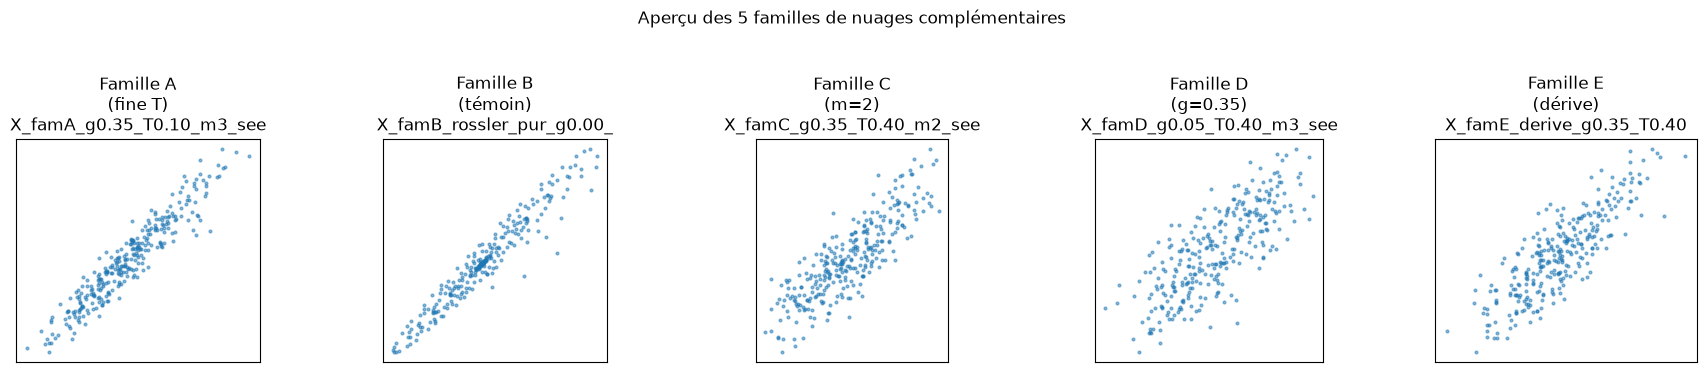

In [10]:
# -----------------------------------------------------------------------------
# APERÇU VISUEL — 1 nuage par famille
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
exemples = [
    (chemins_A[0], "Famille A\n(fine T)"),
    (chemins_B[0], "Famille B\n(témoin)"),
    (chemins_C[0], "Famille C\n(m=2)"),
    (chemins_D[6], "Famille D\n(g=0.35)"),
    (chemins_E[0], "Famille E\n(dérive)"),
]
for ax, (chemin, titre) in zip(axes, exemples):
    X = np.load(chemin)
    ax.scatter(X[:, 0], X[:, 1], s=4, alpha=0.5)
    ax.set_title(titre + "\n" + chemin.name[:25])
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Aperçu des 5 familles de nuages complémentaires", y=1.05)
plt.tight_layout()
plt.savefig(OUT_DIR / "apercu_familles_A_E.png", dpi=140, bbox_inches="tight")
plt.show()

10. **Ajout des nuages de test 04c** 

## Familles du protocole 04c — F, H, I, J, K

Les fichiers utilisent un nommage commun à jetons explicites : `X_fam<F>_<paramètre><valeur>..._seed<S>.npy`. Les paramètres numériques sont écrits en décimaux (par exemple `g0.35`, `T0.40`) ; `m` est toujours présent. Les familles sans couplage utilisent `g0.00` uniquement lorsqu'il a un sens. Les familles J et K conservent leurs paramètres propres (`eps`, `tv`, `ds`) dans le nom.

La génération produit les grilles F/H/I/J/K prévues par N11–N17 : 6 300 nuages au total et 1 750 sidecars R pour J. H ne couvre que T=0.40, avec les trois variantes `phiJ`, `phiI` et `shuf`. Les fichiers sont écrits dans `nuages_complementaires`, lu par le full-run. La cellule de génération est reprenable : elle réutilise les sorties explicitement nommées si leur forme et leurs valeurs sont valides, refuse d'écraser les fichiers invalides, puis vérifie les comptes.

In [11]:
# -----------------------------------------------------------------------------
# CONFIGURATION PROTOCOLE 04C — Familles F, H, I, J, K
# -----------------------------------------------------------------------------
N_SAMPLES = 4000
N_POINTS = 300
TAKENS_TAU = 7
SEEDS = tuple(range(35))

# N11-N13, N16 : grille F normalisée
G_F = tuple(np.round(np.linspace(0.0, 1.0, 11), 2))
T_F = (0.10, 0.20, 0.40, 0.80)
M_F = 3

# N12 : trois nuls structurels de F à T=0.40
H_VARIANTS = ("phiJ", "phiI", "shuf")
T_H = 0.40

# N14 : une variante d'hyperparamètre à la fois, contre la référence F
G_I = (0.10, 0.40, 0.70)
I_VARIANTS = (
    *({"kind": "tau", "tau": tau, "n_points": N_POINTS, "m": 3} for tau in (3, 15, 30)),
    *({"kind": "N", "tau": TAKENS_TAU, "n_points": n_points, "m": 3} for n_points in (150, 600, 1200)),
    {"kind": "m", "tau": TAKENS_TAU, "n_points": N_POINTS, "m": 5},
)

# N15 : Rössler désaccordés, deux directions et une grille dense près de zéro
EPS_J = tuple(np.round(np.r_[np.linspace(0.0, 0.05, 11), np.linspace(0.07, 0.30, 14)], 4))
DIRECTIONS_J = ("uni", "bi")

# N17 : constantes de temps du filtre et vitesse du pilote
TV_K = (0, 5, 10, 20, 40, 80, 160, 320)
DS_K = (1, 2)
T_K = (0.10, 0.40)

EXPECTED_04C = {
    "F": len(G_F) * len(T_F) * len(SEEDS),
    "H": len(H_VARIANTS) * len(G_F) * len(SEEDS),
    "I": len(I_VARIANTS) * len(G_I) * len(SEEDS),
    "J": len(EPS_J) * len(DIRECTIONS_J) * len(SEEDS),
    "K": len(TV_K) * len(DS_K) * len(T_K) * len(SEEDS),
}
EXPECTED_R_J = EXPECTED_04C["J"]
EXPECTED_TOTAL_04C = sum(EXPECTED_04C.values())

print("Configuration 04c prête :", EXPECTED_04C)
print(f"Total : {EXPECTED_TOTAL_04C} nuages + {EXPECTED_R_J} sidecars R pour J.")

Configuration 04c prête : {'F': 1540, 'H': 1155, 'I': 735, 'J': 1750, 'K': 1120}
Total : 6300 nuages + 1750 sidecars R pour J.


In [12]:
# -----------------------------------------------------------------------------
# GÉNÉRATION DES NUAGES 04C — F, H, I, J, K
# -----------------------------------------------------------------------------
from collections import Counter
from scipy.fft import rfft, irfft
from scipy.signal import hilbert

OUT_DIR_04C = OUT_DIR
OUT_DIR_04C.mkdir(parents=True, exist_ok=True)
CHEMINS_04C = {fam: [] for fam in EXPECTED_04C}
SIDECARS_R_J = []
CREES_04C = Counter()
DEJA_PRESENTS_04C = Counter()

def ecrire_array_04c(path, array, shape_attendue):
    """Ecrit atomiquement ; une sortie partielle valide peut être reprise sans écrasement."""
    path = Path(path)
    array = np.asarray(array, dtype=np.float64)
    if array.shape != shape_attendue:
        raise ValueError(f"{path.name} : shape {array.shape}, attendu {shape_attendue}")
    if not np.isfinite(array).all():
        raise ValueError(f"{path.name} : NaN ou inf détecté")
    if path.exists():
        existing = np.load(path, allow_pickle=False)
        if existing.shape != shape_attendue or not np.isfinite(existing).all():
            raise ValueError(f"Fichier existant invalide, non écrasé : {path}")
        return False
    temp_path = path.with_name(path.name + ".tmp")
    try:
        with temp_path.open("wb") as stream:
            np.save(stream, array, allow_pickle=False)
        temp_path.replace(path)
    finally:
        if temp_path.exists():
            temp_path.unlink()
    return True

def sauvegarder_nuage_04c(famille, nom, X, n_points, m):
    path = OUT_DIR_04C / nom
    fresh = ecrire_array_04c(path, X, (n_points, 2 * m))
    CHEMINS_04C[famille].append(path)
    (CREES_04C if fresh else DEJA_PRESENTS_04C)[famille] += 1

def nuage_signaux_04c(s1, s2, m, tau, n_points):
    canaux = [plonger_takens(s1, m, tau), plonger_takens(s2, m, tau)]
    return standardiser(sous_echantillonner(np.hstack(canaux), n_points))

def nuage_canaux_bruites_04c(s1, s2, m, tau, n_points, rng, T):
    return nuage_signaux_04c(perturber(s1, T, rng), perturber(s2, T, rng), m, tau, n_points)

def paire_base_04c(seed):
    rng = np.random.default_rng(seed)
    s1 = standardiser(SIGNAL_FAMILIES["sinus"](rng, N_SAMPLES))
    s2 = standardiser(SIGNAL_FAMILIES["rossler"](rng, N_SAMPLES))
    return s1, s2

def surrogate_phases_04c(s1, s2, rng, phases_jointes):
    f1, f2 = rfft(s1), rfft(s2)
    n = len(s1)
    stop = len(f1) - 1 if n % 2 == 0 else len(f1)
    phi1 = np.zeros(len(f1)); phi2 = np.zeros(len(f2))
    phi1[1:stop] = rng.uniform(0, 2 * np.pi, stop - 1)
    if phases_jointes:
        phi2[1:stop] = phi1[1:stop]
    else:
        phi2[1:stop] = rng.uniform(0, 2 * np.pi, stop - 1)
    x1 = irfft(np.abs(f1) * np.exp(1j * (np.angle(f1) + phi1)), n=n)
    x2 = irfft(np.abs(f2) * np.exp(1j * (np.angle(f2) + phi2)), n=n)
    return x1, x2

def integrer_rossler_couple_04c(eps, direction, seed):
    if direction not in DIRECTIONS_J:
        raise ValueError(f"Direction J inconnue : {direction}")
    rng = np.random.default_rng(seed)
    burn = 1000
    n_total = N_SAMPLES + burn
    x1, y1, z1, x2, y2, z2 = rng.normal(scale=0.5, size=6)
    X1, X2 = np.empty(n_total), np.empty(n_total)
    dt = 0.03
    for i in range(n_total):
        X1[i], X2[i] = x1, x2
        c12 = eps * (x2 - x1) if direction == "bi" else 0.0
        c21 = eps * (x1 - x2)
        dx1, dy1, dz1 = -y1 - z1 + c12, x1 + 0.2 * y1, 0.2 + z1 * (x1 - 5.7)
        dx2, dy2, dz2 = -y2 - z2 + c21, x2 + 0.2 * y2, 0.2 + z2 * (x2 - 5.9)
        x1, y1, z1 = x1 + dt * dx1, y1 + dt * dy1, z1 + dt * dz1
        x2, y2, z2 = x2 + dt * dx2, y2 + dt * dy2, z2 + dt * dz2
    return X1[burn:], X2[burn:]

def coherence_phase_04c(s1, s2):
    dphi = np.angle(hilbert(s1)) - np.angle(hilbert(s2))
    return float(np.abs(np.mean(np.exp(1j * dphi))))


def integrer_rossler_couple_commande_04c(eps, direction, seed):
    """Dynamique J alignée sur la COMMANDE."""
    if direction not in DIRECTIONS_J:
        raise ValueError(f"Direction J inconnue : {direction}")

    # Paramètres exacts de la COMMANDE
    w1, w2 = 0.99, 0.95
    a, b, c1, c2 = 0.2, 0.2, 5.7, 5.7
    dt = 0.03
    burn = 1000

    # Même état initial pour tous les eps et directions d'un seed
    r0 = np.random.default_rng(70_000 + seed)
    st = r0.normal(scale=0.5, size=6)

    xs = np.empty((N_SAMPLES, 2))

    for i in range(N_SAMPLES + burn):
        x1, y1, z1, x2, y2, z2 = st

        d1 = np.array([
            -w1 * y1 - z1
            + (eps * (x2 - x1) if direction == "bi" else 0.0),
            w1 * x1 + a * y1,
            b + z1 * (x1 - c1)
        ])

        d2 = np.array([
            -w2 * y2 - z2 + eps * (x1 - x2),
            w2 * x2 + a * y2,
            b + z2 * (x2 - c2)
        ])

        # Même schéma d'Euler explicite
        st = st + dt * np.concatenate([d1, d2])

        # Même convention temporelle que la COMMANDE :
        # mise à jour, puis enregistrement
        if i >= burn:
            xs[i - burn] = (st[0], st[3])

    return xs[:, 0], xs[:, 1]
## added

def coherence_phase_commande_04c(s1, s2):
    """Synchronisation de phase calculée comme dans la COMMANDE."""
    ph = (
        np.angle(hilbert(s1 - s1.mean()))
        - np.angle(hilbert(s2 - s2.mean()))
    )
    return float(np.abs(np.mean(np.exp(1j * ph))))
## added _commande sur integrer_rossler and coherence_phase enlever les précedents apres tests

def filtrer_exponentiel_04c(signal, tau):
    if tau == 0:
        return signal.copy()
    alpha = 1.0 - np.exp(-1.0 / tau)
    out = np.empty_like(signal)
    out[0] = signal[0]
    for i in range(1, len(signal)):
        out[i] = out[i - 1] + alpha * (signal[i] - out[i - 1])
    return out

print(f"Sortie : {OUT_DIR_04C.resolve()}")
print(f"Génération attendue : {EXPECTED_TOTAL_04C} nuages et {EXPECTED_R_J} sidecars R.")

# F : sinus et Rössler standardisés avant le mélange ; bruit ajouté après le couplage.
for seed in SEEDS:
    s1_base, s2_base = paire_base_04c(seed)
    for gi, g in enumerate(G_F):
        s1_c, s2_c = coupler(s1_base, s2_base, float(g))
        for ti, T in enumerate(T_F):
            rng = np.random.default_rng(np.random.SeedSequence([seed, gi, ti, 11]))
            s1n, s2n = perturber(s1_c, T, rng), perturber(s2_c, T, rng)
            X = nuage_signaux_04c(s1n, s2n, M_F, TAKENS_TAU, N_POINTS)
            nom = f"X_famF_g{g:.2f}_T{T:.2f}_m{M_F}_seed{seed}.npy"
            sauvegarder_nuage_04c("F", nom, X, N_POINTS, M_F)
            if np.isclose(T, T_H):
                rng_h = np.random.default_rng(np.random.SeedSequence([seed, gi, 12]))
                for variante in H_VARIANTS:
                    if variante == "phiJ":
                        h1, h2 = surrogate_phases_04c(s1n, s2n, rng_h, phases_jointes=True)
                    elif variante == "phiI":
                        h1, h2 = surrogate_phases_04c(s1n, s2n, rng_h, phases_jointes=False)
                    else:
                        ordre = rng_h.permutation(len(s1n))
                        h1, h2 = s1n[ordre], s2n[ordre]
                    H = nuage_signaux_04c(h1, h2, M_F, TAKENS_TAU, N_POINTS)
                    nom_h = f"X_famH_{variante}_g{g:.2f}_T{T:.2f}_m{M_F}_seed{seed}.npy"
                    sauvegarder_nuage_04c("H", nom_h, H, N_POINTS, M_F)

# I : une variation de tau, N (nombre de points) ou m, par rapport à F.
for seed in SEEDS:
    s1_base, s2_base = paire_base_04c(seed)
    for gi, g in enumerate(G_I):
        s1_c, s2_c = coupler(s1_base, s2_base, float(g))
        for vi, spec in enumerate(I_VARIANTS):
            tau, n_points, m = spec["tau"], spec["n_points"], spec["m"]
            rng = np.random.default_rng(np.random.SeedSequence([seed, gi, vi, 14]))
            X = nuage_canaux_bruites_04c(s1_c, s2_c, m, tau, n_points, rng, 0.40)
            nom = (f"X_famI_tau{tau}_N{n_points:04d}_g{g:.2f}_T0.40_"
                   f"m{m}_seed{seed}.npy")
            sauvegarder_nuage_04c("I", nom, X, n_points, m)

# J **A_CORRIGER*** : deux Rössler désaccordés, unidirectionnel (pilote -> répondant) ou bidirectionnel.
# DELETED

# J : dynamique alignée sur la COMMANDE
for seed in SEEDS:
    # La COMMANDE réutilise les mêmes réalisations de bruit
    # pour toutes les directions et valeurs de eps d'un seed.
    noise = np.random.default_rng(71_000 + seed)
    n1 = noise.normal(size=N_SAMPLES)
    n2 = noise.normal(size=N_SAMPLES)

    for direction in DIRECTIONS_J:
        for eps in EPS_J:
            eps = float(eps)

            s1, s2 = integrer_rossler_couple_commande_04c(
                eps, direction, seed
            )

            R = coherence_phase_commande_04c(s1, s2)

            # Séries bruitées selon la COMMANDE
            s1n = s1 + 0.10 * s1.std() * n1
            s2n = s2 + 0.10 * s2.std() * n2

            # Nom commun pour le nuage et sa mesure R
            nom = (
                f"X_famJ_{direction}_eps{eps:.4f}"
                f"_T0.10_m3_seed{seed}.npy"
            )

            # IMPORTANT :
            # Cette étape doit reconstruire le nuage à partir de s1n/s2n
            # SANS ajouter une seconde couche de bruit.
            #
            # Voir le point 4 ci-dessous pour l'adaptateur à utiliser.
            # MODIFIED_:
            # s1n et s2n ont déjà reçu le bruit prescrit par la COMMANDE.
            X = nuage_signaux_04c(
                s1n, s2n, 3, TAKENS_TAU, N_POINTS
            )
            #_
            sauvegarder_nuage_04c("J", nom, X, N_POINTS, 3)

            sidecar = OUT_DIR_04C / nom.replace("X_famJ_", "R_famJ_")
            fresh = ecrire_array_04c(
                sidecar, np.asarray(R), ()
            )

            SIDECARS_R_J.append(sidecar)
            (CREES_04C if fresh else DEJA_PRESENTS_04C)["R_J"] += 1            

# K : pilote Rössler ralenti, puis filtré pour former le second canal.
for ds in DS_K:
    for seed in SEEDS:
        rng_source = np.random.default_rng(np.random.SeedSequence([seed, ds, 17]))
        pilote = signal_rossler(rng_source, N_SAMPLES, dt=0.03 / ds)
        for tv in TV_K:
            eau = filtrer_exponentiel_04c(pilote, tv)
            for T in T_K:
                rng = np.random.default_rng(np.random.SeedSequence([seed, ds, tv, int(T * 100), 18]))
                X = nuage_canaux_bruites_04c(pilote, eau, 3, TAKENS_TAU, N_POINTS, rng, T)
                nom = f"X_famK_tv{tv}_ds{ds}_T{T:.2f}_m3_seed{seed}.npy"
                sauvegarder_nuage_04c("K", nom, X, N_POINTS, 3)

for famille, attendu in EXPECTED_04C.items():
    chemins = CHEMINS_04C[famille]
    if len(chemins) != attendu or len({path.name for path in chemins}) != attendu:
        raise RuntimeError(f"Famille {famille} : {len(chemins)} chemins uniques, {attendu} attendus")
    if not all(path.is_file() for path in chemins):
        raise RuntimeError(f"Famille {famille} : au moins un fichier attendu manque sur disque")
if len(SIDECARS_R_J) != EXPECTED_R_J or len({path.name for path in SIDECARS_R_J}) != EXPECTED_R_J:
    raise RuntimeError(f"Sidecars R J : {len(SIDECARS_R_J)}, {EXPECTED_R_J} attendus")
print("Génération 04c terminée ; comptes vérifiés :", {fam: len(paths) for fam, paths in CHEMINS_04C.items()})
print("Nouveaux fichiers :", dict(CREES_04C), "; sorties valides reprises :", dict(DEJA_PRESENTS_04C))

Sortie : C:\Users\anton\source\Takens_H0_Simondon_in_PHY_noether-surphin-suite_forPUB\nuages_complementaires
Génération attendue : 6300 nuages et 1750 sidecars R.
Génération 04c terminée ; comptes vérifiés : {'F': 1540, 'H': 1155, 'I': 735, 'J': 1750, 'K': 1120}
Nouveaux fichiers : {'F': 1540, 'H': 1155, 'I': 735, 'J': 1750, 'R_J': 1750, 'K': 1120} ; sorties valides reprises : {}
